(paramfit_pocomc_ntbk)=

# Parameters fit with pocoMC

This is an example of how we can use [pocoMC](https://pocomc.readthedocs.io/) to estimate the fundamental parameters of an observed cluster. pocoMC implements Preconditioned Monte Carlo, a Sequential Monte Carlo method that moves a set of particles from the prior to the posterior by slowly increasing the weight given to the likelihood. Unlike the ABC approach used in the [Parameters fit with pyABC](paramfit_ntbk) tutorial, pocoMC needs an actual (log-)likelihood, which we build from the **ASteCA** [Likelihood](asteca.Likelihood) object.

The user can combine **ASteCA** with any other package of their choosing, here's a list with many Python-based [MCMC and ABC packages](https://gabriel-p.github.io/pythonMCMC/).

## Loading ASteCA objects

We start by instantiating an [Isochrones](asteca.Isochrones) object with a PARSEC isochrone. This is an example file but you can use whatever isochrone service fits your needs:

In [1]:
import asteca

# Load isochrones
isochs = asteca.Isochrones(
    model='parsec',
    isochs_path="../../_static/isochrones/parsec/",
    mag="Gmag",
    color=("G_BPmag", "G_RPmag"),
    magnitude_effl=6390.7,
    color_effl=(5182.58, 7825.08),
    verbose=2
)


Instantiating isochrones
Model          : PARSEC
N_files        : 1
N_mets         : 5
N_ages         : 13
N_points       : 2000
z    range     : [0.01, 0.03]
loga range     : [7.0, 10.0]
Magnitude      : Gmag
Color          : G_BPmag-G_RPmag
Isochrone object generated


Next we instantiate a [Synthetic](asteca.Synthetic) object, passing the `isochs` object we just created (we are using all defaults for the arguments here):

In [2]:
# Create Synthetic cluster object
synthcl = asteca.Synthetic(isochs, seed=457304, verbose=2)


Instantiating synthetic
(Sampling IMF)
Default params : {'met': 0.0152, 'loga': 8.0, 'alpha': 0.09, 'beta': 0.94, 'Rv': 3.1, 'DR': 0.0, 'Av': 0.2, 'dm': 9.0}
Extinction law : CCMO
Diff reddening : foreground
IMF            : chabrier_2014
Max init mass  : 10000
Gamma dist     : D&K
Random seed    : 457304
Synthetic clusters object generated


Now we load our observed cluster into a [Cluster](asteca.Cluster) object:

In [3]:
import pandas as pd

obs_df = pd.read_csv("../../_static/cluster.csv")

my_cluster = asteca.Cluster(
    ra=obs_df["RA_ICRS"],
    dec=obs_df["DE_ICRS"], 
    mag=obs_df["Gmag"],
    e_mag=obs_df["e_Gmag"],
    color=obs_df["BP-RP"],
    e_color=obs_df["e_BP-RP"],
    verbose=2
)


Instantiating cluster from data
Columns read   : ra, dec, mag, e_mag, color, e_color
N_stars        : 1428
N_nan_phot     : 9
N_clust_min    : 25
N_clust_max    : 2000
Cluster object generated


We assume that the cluster file loaded in `obs_df` is composed of only the most probable members of the cluster. If not, you can refer to the [Membership probabilities](membership) tutorial to learn how to obtain the membership probabilities and select the most probable members.

Finally, we need to calibrate our `synthcl` object and instantiate a [Likelihood](asteca.Likelihood) object, which will be used to quantify how similar our observed cluster is to the generated synthetic clusters. For both operations we need to pass the `my_cluster` object we generated above.

In [4]:
# Calibrate the `synthcl` object
synthcl.calibrate(my_cluster)

# Instantiate the likelihood
likelihood = asteca.Likelihood(my_cluster)


Calibrated observed cluster
N_stars_obs    : 1419
Max magnitude  : 18.99
Error distribution loaded

Likelihood object generated


## Running pocoMC

We are now ready to estimate the fundamental parameters with pocoMC. The first step is to import pocoMC and define the priors for the parameters that are being estimated. The parameters that are *not* estimated keep the default values shown when the `synthcl` object was created.

pocoMC accepts any list of `scipy.stats` distributions as priors. Notice that, as in the pyABC case, the uniform distributions in `scipy.stats` require the minimum value and the *range*, not the maximum value.

In [5]:
import numpy as np
import pocomc
from scipy import stats

# Ranges for the fitted parameters
priors_dict = {
    "met": (0.01, 0.02),
    "loga": (7.0, 9.5),
    "dm": (8.0, 10.5),
    "Av": (0.0, 2.0),
}
names = list(priors_dict)

# Uniform priors for all the parameters. The user can of course change this as desired,
# see the pocoMC docs for more information.
prior = pocomc.Prior(
    [stats.uniform(pmin, pmax - pmin) for pmin, pmax in priors_dict.values()]
)

Next we define the log-likelihood function. It takes an array with the values of the fitted parameters (in the same order as the priors above), generates a synthetic cluster via the `generate()` method, and compares it with the observed cluster via the `likelihood` object.

The log-likelihood is obtained with the `likelihood.log_lkl()` method, which returns the log of the Poisson Likelihood Ratio (see [Likelihood](../likelihood_mod)) relative to its maximum value, so that `0` means a perfect match.

Its `temperature` argument divides the log-likelihood: a value of `1` gives the posterior of the Poisson likelihood ratio, while values larger than `1` widen the posterior. The synthetic clusters are only an approximation of a real cluster, and for clusters with many members a `temperature` of `1` gives uncertainties that are too small. For clusters with few members, on the other hand, values larger than `1` give uncertainties that are too large and worse fits.

We set the `temperature` with a simple rule that depends on the number of members $N$:

| $N$ | `temperature` |
|---|---|
| $N \leq 150$ | 1 |
| $150 < N \leq 400$ | 2 |
| $N > 400$ | 4 |

This is a **heuristic rule**, not derived from first principles: it was calibrated on simulated clusters (so that the 16th-84th percentile range contains the true values for close to 68% of them) and checked on a set of real clusters. It is a reasonable starting point, but users can change it to suit their own data.

Parameter combinations that produce an empty synthetic cluster (e.g. too far away), or a synthetic cluster with no stars in the region of the observed one, are given a very low log-likelihood (see [Likelihood](../likelihood_mod)). Non-finite values are not expected, but are given a log-likelihood of `-inf` as a safety check.

In [6]:
# Heuristic temperature as a function of the number of members, as
# (max N, temperature) pairs: the first pair with N <= max N applies
N_temperatures = ((150, 1.0), (400, 2.0), (np.inf, 4.0))
temperature = next(T for N_max, T in N_temperatures if my_cluster.N_stars <= N_max)
print(f"N={my_cluster.N_stars}, temperature={temperature:g}")

def log_like(params):
    """Log-likelihood of the fitted parameters."""
    # Generate a synthetic cluster with these parameters
    synth_clust = synthcl.generate(dict(zip(names, params)))
    # Tempered log-likelihood of the synthetic cluster (0 means a perfect match)
    lnl = likelihood.log_lkl(synth_clust, temperature)
    # Non-finite values are not expected; reject them as a safety check
    return lnl if np.isfinite(lnl) else -np.inf

N=1428, temperature=4


We create a [Sampler](https://pocomc.readthedocs.io/en/latest/api.html) object with the priors and the log-likelihood function. The `n_effective` and `n_active` arguments set the number of particles used. We use 256 and 128 particles, with `n_total=512`. In tests on 100 simulated and 50 real UCC clusters, these values took a little more than half the time of twice as many particles, with the same accuracy and uncertainties. Halving them again made the uncertainties too small. We turn off the preconditioning (`precondition=False`) because training the normalizing flow is slow on a CPU and, for this problem, it gives the same results.

The run stops when the posterior is reached and `n_total` effective samples are available. This takes less than a minute here:

In [7]:
import time

sampler = pocomc.Sampler(
    prior,
    log_like,
    n_effective=256,
    n_active=128,
    precondition=False,
    random_state=457304,
)
t0 = time.perf_counter()
sampler.run(n_total=512, n_evidence=0, progress=False)
print(f"Run time: {time.perf_counter() - t0:.1f} s")

Run time: 7.9 s


## Extracting the results

We extract the posterior samples and their importance weights. We use the weights to show the effective sample size, which should be large enough to allow decent median/STDDEV values to be extracted.

In [8]:
# Weighted posterior samples
samples, weights, _, _ = sampler.posterior()

ESS = weights.sum() ** 2 / (weights**2).sum()
print("Effective sample size: {:.0f}".format(ESS))

Effective sample size: 507


The estimations for each fitted parameter are obtained from the resampled (i.e. equally weighted) posterior samples:

In [9]:
# Equally weighted posterior samples
samples, _, _ = sampler.posterior(resample=True)

print("\nParameters estimation:")
print("----------------------")
fit_params = {}
for i, k in enumerate(names):
    # Extract medians for the fitted parameters
    _median = np.median(samples[:, i])
    fit_params[k] = _median
    # Extract STDDEV for the fitted parameters
    _std = np.std(samples[:, i])
    print("{:<5}: {:.3f} +/- {:.3f}".format(k, _median, _std))


Parameters estimation:
----------------------
met  : 0.015 +/- 0.002
loga : 7.935 +/- 0.100
dm   : 8.199 +/- 0.084
Av   : 0.510 +/- 0.092


pocoMC does not include its own plotting functions, but the samples can be passed to any package. Here we use [corner](https://corner.readthedocs.io/) to show the 1D and 2D posterior distributions:

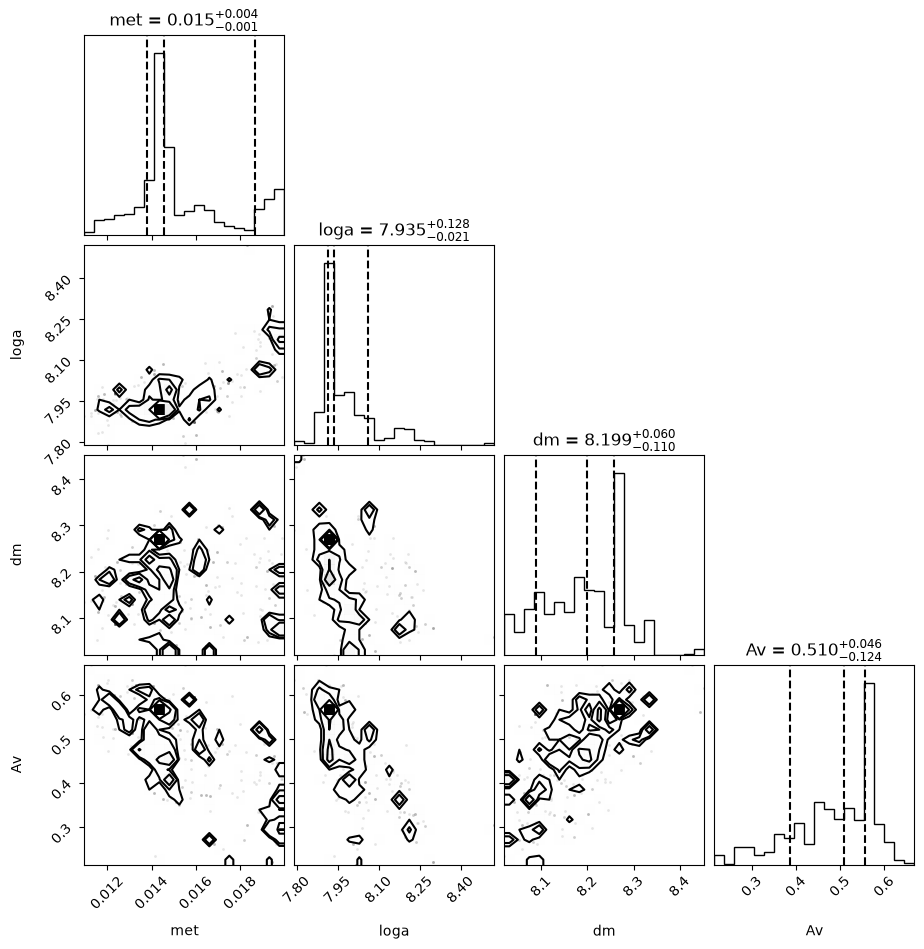

In [10]:
import corner

corner.corner(
    samples,
    labels=names,
    quantiles=(0.16, 0.5, 0.84),
    show_titles=True,
    title_fmt=".3f",
);

We can generate a CMD comparing our observed cluster with the synthetic cluster generated with the medians, using the medians of the parameter distributions stored in the `fit_params` dictionary:

In [11]:
# Generate the synthetic cluster using these parameters
synth_arr = synthcl.generate(fit_params)

### Goodness of fit

The distance returned by the `likelihood` object is useful to compare synthetic clusters for the *same* observed cluster, but its value can not be compared across clusters (even a perfect model gives a distance larger than zero, by an amount that depends on the number of stars). To assess whether this synthetic cluster is a good representation of the observed cluster we use the [cmd_overlap()](asteca.Likelihood.cmd_overlap) method (see {ref}`Goodness of fit <cmd_overlap>`).

In [12]:
# Distance between the observed cluster and this synthetic cluster
dist = likelihood.dist(synth_arr)
print("Distance       : {:.3f}".format(dist))

# CMD overlap between the observed cluster and this synthetic cluster
D, D_std = likelihood.cmd_overlap(synth_arr)
print("CMD overlap (D): {:.3f} +/- {:.3f}".format(D, D_std))

Distance       : 0.051
CMD overlap (D): 0.047 +/- 0.003


Finally, we can generate a side-by-side CMD plot showing also the theoretical isochrone associated to this synthetic cluster:

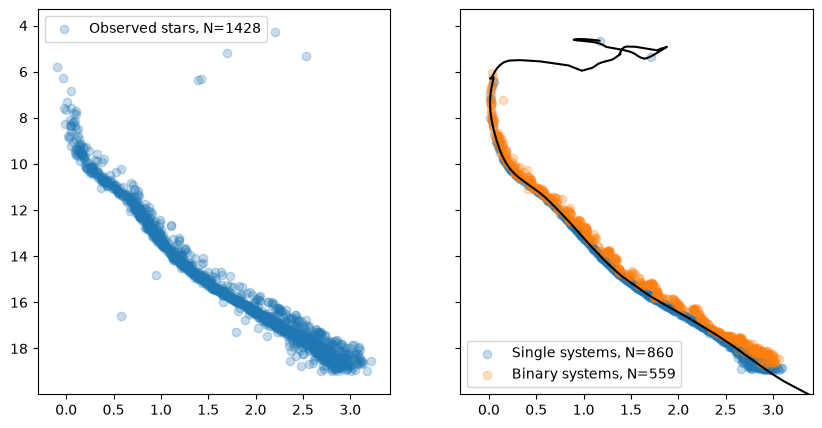

In [13]:
import matplotlib.pyplot as plt
import numpy as np

def cmd_plot(color, mag, label, ax=None):
    """Function to generate a CMD plot"""
    if ax is None:
        ax = plt.subplot(111)
    label = label + f", N={len(mag)}"
    ax.scatter(color, mag, alpha=0.25, label=label)
    ax.legend()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
# Observed cluster
cmd_plot(my_cluster.color, my_cluster.mag, "Observed stars", ax1)

# Synthetic cluster
# Boolean mask identifying the binary systems
binary_msk = ~np.isnan(synth_arr[-1])
# Extract magnitude and color
mag, color = synth_arr[0], synth_arr[1]
# Plot single systems
cmd_plot(color[~binary_msk], mag[~binary_msk], "Single systems", ax2)
# Plot binary systems
cmd_plot(color[binary_msk], mag[binary_msk], "Binary systems", ax2)

# Get isochrone associated to the synthetic cluster
isoch_arr = synthcl.get_isochrone(fit_params)
# Plot the isochrone
ax2.plot(isoch_arr[1], isoch_arr[0], c="k")

# Same ranges in both plots, defined by the observed cluster (inverted y axis)
ax1.set_xlim(np.nanmin(my_cluster.color) - 0.2, np.nanmax(my_cluster.color) + 0.2)
ax1.set_ylim(np.nanmax(my_cluster.mag) + 1, np.nanmin(my_cluster.mag) - 1);

## Faster runs: evaluating the particles in batches

Most of the run time is spent generating synthetic clusters, one per call to `log_like()`. With `vectorize=True`, pocoMC instead passes all the active particles of a step to the log-likelihood in a single call, as an array of shape `(n_active, n_params)`. These are evaluated at once with [Likelihood.log_lkl_batch()](asteca.Likelihood.log_lkl_batch), which returns the same values as `log_like()`. With [numba](https://numba.pydata.org/) installed it removes the Python overhead of each model, and with `parallel=True` it also distributes the models among the CPU cores. **Without numba there is no speedup**. See [Log-likelihoods in batches](ref_log_lkl_batch) for the details, e.g.: how to set the number of threads.

The vectorized log-likelihood converts the array of particles into the parameters dictionary (one column per parameter):

In [15]:
def log_like_vec(params_arr):
    """Log-likelihood of an array of fitted parameters, of shape (n_active, n_params)"""
    lnl = likelihood.log_lkl_batch(
        synthcl, dict(zip(names, params_arr.T)), temperature, parallel=True
    )
    # Non-finite values are not expected; reject them as a safety check
    lnl[~np.isfinite(lnl)] = -np.inf
    return lnl

We run pocoMC again with the same arguments and seed, adding `vectorize=True`. The first call to `log_lkl_batch()` includes the compilation of the numba functions, which are then cached for later sessions. The time saved depends on the number of stars in the cluster and on the number of CPU cores.

In [16]:
sampler_batch = pocomc.Sampler(
    prior,
    log_like_vec,
    n_effective=256,
    n_active=128,
    precondition=False,
    vectorize=True,
    random_state=457304,
)
t0 = time.perf_counter()
sampler_batch.run(n_total=512, n_evidence=0, progress=False)
print(f"Run time: {time.perf_counter() - t0:.1f} s")

Run time: 3.5 s


Since the log-likelihood values are identical, so are the (weighted) posterior samples obtained with the same seed:

In [17]:
samples_w, weights_w, _, _ = sampler.posterior()
samples_b, weights_b, _, _ = sampler_batch.posterior()
print("Identical samples:", np.array_equal(samples_w, samples_b))
print("Identical weights:", np.array_equal(weights_w, weights_b))

Identical samples: True
Identical weights: True
